<a href="https://colab.research.google.com/github/lakshanya-j/Projects/blob/main/SegmentationAndAnomalyDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

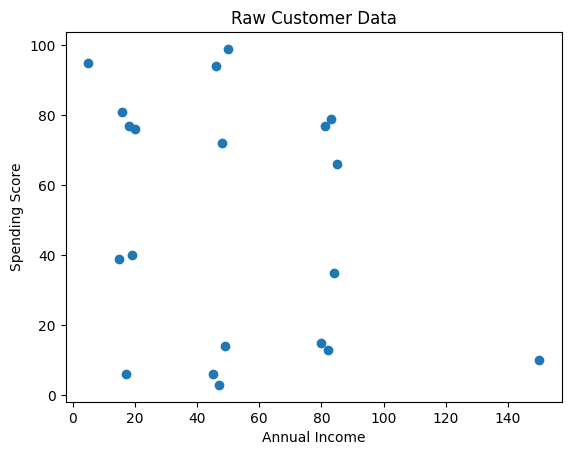

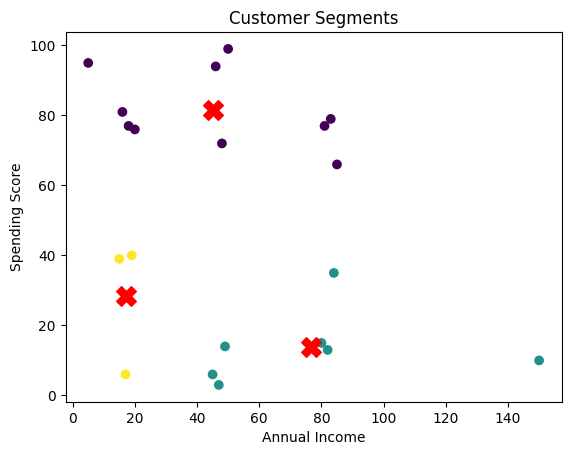

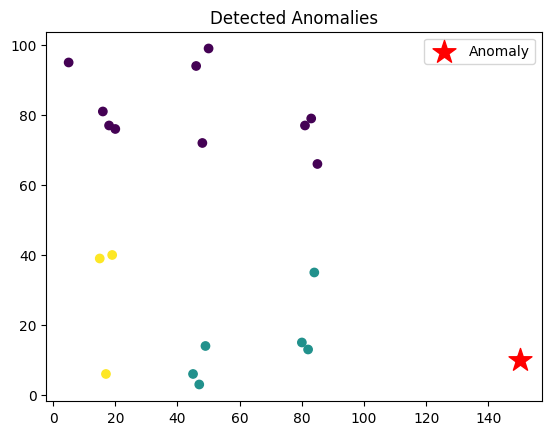

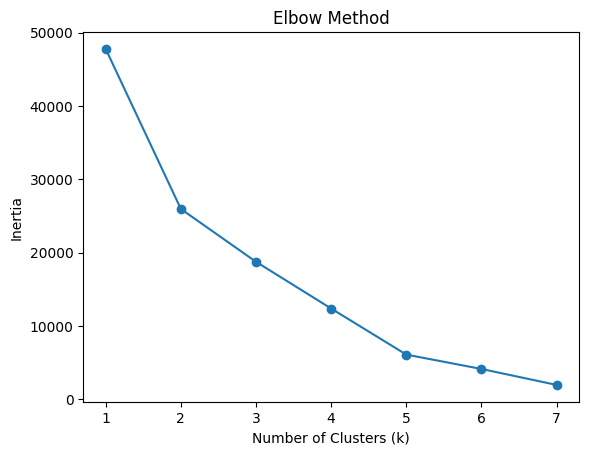

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

data = {
    "CustomerID": range(1, 21),
    "AnnualIncome": [15,16,17,18,19,20,45,46,47,48,49,50,80,81,82,83,84,85,150,5],
    "SpendingScore": [39,81,6,77,40,76,6,94,3,72,14,99,15,77,13,79,35,66,10,95]
}
df = pd.DataFrame(data)
df.head()

plt.scatter(df["AnnualIncome"], df["SpendingScore"])
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Raw Customer Data")
plt.show()


X = df[["AnnualIncome", "SpendingScore"]]
kmeans = KMeans(n_clusters=3, random_state=42)
df["Segment"] = kmeans.fit_predict(X)

plt.scatter(df["AnnualIncome"], df["SpendingScore"], c=df["Segment"], cmap="viridis")
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], c="red", marker="X", s=200)
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segments")
plt.show()

centroids = kmeans.cluster_centers_
df["DistanceToCentroid"] = df.apply(
    lambda row: np.linalg.norm([row["AnnualIncome"], row["SpendingScore"]] - centroids[row["Segment"]]),
    axis=1
)
threshold = df["DistanceToCentroid"].mean() + 2 * df["DistanceToCentroid"].std()
df["Anomaly"] = df["DistanceToCentroid"] > threshold
df[df["Anomaly"] == True]

plt.scatter(df["AnnualIncome"], df["SpendingScore"], c=df["Segment"], cmap="viridis")
plt.scatter(df[df["Anomaly"]]["AnnualIncome"], df[df["Anomaly"]]["SpendingScore"], c="red", marker="*", s=300, label="Anomaly")
plt.legend()
plt.title("Detected Anomalies")
plt.show()


inertia = []
k_range = range(1, 8)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X)
    inertia.append(km.inertia_)

plt.plot(k_range, inertia, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()